# 🤖 Lecture 2 — LLMs & Chatbots
## Lab Notebook

**Στόχοι του lab:**
- Κάνω το πρώτο μου API call σε LLM
- Πειραματίζομαι με prompt engineering (zero-shot, few-shot, CoT)
- Χτίζω multi-turn συνομιλία με chat history
- Ελέγχω τη δημιουργικότητα μέσω temperature
- Φτιάχνω interactive chatbot με ipywidgets

**Απαιτήσεις:**
```
pip install openai ipywidgets
# Για τοπικό LLM (optional): ollama pull llama3.2
```


In [2]:
!sudo apt-get install -y zstd
!curl -fsSL https://ollama.com/install.sh | sh


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  zstd
0 upgraded, 1 newly installed, 0 to remove and 51 not upgraded.
Need to get 603 kB of archives.
After this operation, 1,695 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 zstd amd64 1.4.8+dfsg-3build1 [603 kB]
Fetched 603 kB in 1s (1,091 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package zstd.
(Reading database ... 122402 files and directories currently

In [3]:
import subprocess, time

subprocess.Popen(
    ["ollama", "serve"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
)
time.sleep(5)  # περίμενε να εκκινήσει
print("Ollama server started")

Ollama server started


---
## ⚙️ Section 1 — Setup & Knobs

Πριν ξεκινήσουμε, ρυθμίζουμε τις παραμέτρους:
- `USE_OPENAI = True` → χρησιμοποιεί το OpenAI API (χρειάζεται key)
- `USE_OLLAMA = True` → χρησιμοποιεί τοπικό μοντέλο μέσω Ollama
- Αν και τα δύο `False` → template fallback (για demo χωρίς API)


In [4]:
# ── Knobs ──────────────────────────────────────────────────────────────────
USE_OPENAI   = False          # True: χρησιμοποιεί OpenAI API
USE_OLLAMA   = True         # True: χρησιμοποιεί τοπικό Ollama
OPENAI_API_KEY = "sk-..."    # ← βάλε το κλειδί σου
OPENAI_MODEL   = "gpt-4o-mini"
OLLAMA_MODEL   = "llama3.2"

# ── Imports ────────────────────────────────────────────────────────────────
import os, json, textwrap
from IPython.display import display, Markdown

# ── C_PLOT palette (για plots) ──────────────────────────────────────────────
C_PLOT = {
    "navy":   "#0F1F3D",
    "teal":   "#0891B2",
    "cyan":   "#06B6D4",
    "gold":   "#F59E0B",
    "coral":  "#F96167",
    "green":  "#16A34A",
    "gray":   "#64748B",
    "light":  "#EEF4FF",
}

# ── LLM client setup ───────────────────────────────────────────────────────
_openai_client = None

def get_client():
    global _openai_client
    if USE_OPENAI and _openai_client is None:
        from openai import OpenAI
        _openai_client = OpenAI(api_key=OPENAI_API_KEY)
    return _openai_client

print("✅ Setup complete")
if USE_OPENAI:
    print(f"   Μοντέλο: {OPENAI_MODEL} (OpenAI)")
elif USE_OLLAMA:
    print(f"   Μοντέλο: {OLLAMA_MODEL} (Ollama — τοπικό)")
else:
    print("   Template fallback mode (χωρίς API)")


✅ Setup complete
   Μοντέλο: llama3.2 (Ollama — τοπικό)


---
## 💬 Section 2 — Πρώτο API Call

Ας στείλουμε το πρώτο μήνυμα στο LLM και να δούμε τη δομή της απάντησης.

**Δομή messages:**
```
system  → ρόλος / οδηγίες για το μοντέλο
user    → η ερώτησή μας
assistant → η απάντηση (γεμίζει αυτόματα)
```


In [5]:
!pip install ollama

In [6]:
!ollama pull llama3.2

In [7]:
# ── Βοηθητική συνάρτηση: ένα απλό call ──────────────────────────────────
def simple_call(user_msg, system_msg="Είσαι χρήσιμος βοηθός.", temperature=0.7, max_tokens=300):
    """Κάνει ένα API call και επιστρέφει το κείμενο απάντησης."""
    messages = [
        {"role": "system",  "content": system_msg},
        {"role": "user",    "content": user_msg},
    ]
    if USE_OPENAI:
        client = get_client()
        resp = client.chat.completions.create(
            model=OPENAI_MODEL,
            messages=messages,
            temperature=temperature,
            max_tokens=max_tokens,
        )
        return resp.choices[0].message.content

    elif USE_OLLAMA:
        import ollama
        resp = ollama.chat(
            model=OLLAMA_MODEL,
            messages=messages,
            options={"temperature": temperature, "num_predict": max_tokens},
        )
        return resp['message']['content']

    else:
        # Template fallback
        return f"[Template] Ερώτηση: '{user_msg}' | System: '{system_msg[:50]}...'"


# ── Πρώτο call ──────────────────────────────────────────────────────────────
answer = simple_call("Τι είναι ένα Large Language Model; Εξήγησέ το σε 2 προτάσεις.")
print("🤖 Απάντηση:")
print(answer)


🤖 Απάντηση:
Un Large Language Model (LLM) είναι μια μορφή αύτοματης ανάλυσηςภาษής που χρησιμοποιεί μαζική ποικιλία και ενημέρωση για να αναπαραστάσει κοινές μορφές και σχέδια στην γλώσσα, مما τοทำให να δραστηριοποιείται με εξαιρετική γνosenτική πίστη και να αντιμετωπίζει πρόβληματα κατανόησης και συνταξιοδότηση.


### 🔍 Ανάλυση της Απάντησης

Τώρα βλέπουμε ολόκληρο το response object — όχι μόνο το κείμενο.


In [8]:
# Πλήρες response object (μόνο για OpenAI)
if USE_OPENAI:
    client = get_client()
    full_resp = client.chat.completions.create(
        model=OPENAI_MODEL,
        messages=[
            {"role": "system", "content": "Είσαι χρήσιμος βοηθός."},
            {"role": "user",   "content": "Πες μου μια σύντομη φράση στα ελληνικά."},
        ],
        temperature=0.7,
        max_tokens=50,
    )
    print("📦 Response object:")
    print(f"  id:                {full_resp.id}")
    print(f"  model:             {full_resp.model}")
    print(f"  finish_reason:     {full_resp.choices[0].finish_reason}")
    print(f"  prompt_tokens:     {full_resp.usage.prompt_tokens}")
    print(f"  completion_tokens: {full_resp.usage.completion_tokens}")
    print(f"  total_tokens:      {full_resp.usage.total_tokens}")
    print(f"  content:           {full_resp.choices[0].message.content}")
else:
    print("(Διαθέσιμο μόνο με USE_OPENAI=True)")


(Διαθέσιμο μόνο με USE_OPENAI=True)


---
## 🎯 Section 3 — Prompt Engineering

### 3.1 Zero-shot vs Few-shot vs Chain-of-Thought

Θα δούμε πώς αλλάζει η ποιότητα απάντησης ανάλογα με το πώς δομούμε το prompt.


In [9]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── Task: Sentiment classification ──────────────────────────────────────────
reviews = [
    "Το προϊόν ήταν εκπληκτικό, το συστήνω ανεπιφύλακτα!",
    "Απαίσια εμπειρία, δεν θα αγοράσω ξανά.",
    "Εντάξει, χωρίς να ξεχωρίζει ιδιαίτερα.",
]

# ── Zero-shot ─────────────────────────────────────────────────────────────
print("=" * 60)
print("📌 ZERO-SHOT: Κατηγοριοποίηση χωρίς παραδείγματα")
print("=" * 60)

for rev in reviews:
    prompt = f"Κατηγοριοποίησε το sentiment αυτής της κριτικής σε: ΘΕΤΙΚΟ, ΑΡΝΗΤΙΚΟ, ή ΟΥΔΕΤΕΡΟ.\nΚριτική: '{rev}'\nΑπάντηση (μόνο μία λέξη):"
    result = simple_call(prompt, temperature=0.0, max_tokens=10)
    print(f"  '{rev[:45]}...' → {result.strip()}")


📌 ZERO-SHOT: Κατηγοριοποίηση χωρίς παραδείγματα
  'Το προϊόν ήταν εκπληκτικό, το συστήνω ανεπιφύ...' → ΘΕΤΙΚΟ.
  'Απαίσια εμπειρία, δεν θα αγοράσω ξανά....' → ΘΕΤΙΚΟ.
  'Εντάξει, χωρίς να ξεχωρίζει ιδιαίτερα....' → Θετικός.


In [10]:
# ── Few-shot ──────────────────────────────────────────────────────────────
print("=" * 60)
print("📌 FEW-SHOT: Με 2 παραδείγματα")
print("=" * 60)

few_shot_prompt_template = """Κατηγοριοποίησε το sentiment. Παραδείγματα:

'Υπέροχο!' → ΘΕΤΙΚΟ
'Χάλια, απογοητεύτηκα.' → ΑΡΝΗΤΙΚΟ

Κριτική: '{review}'
Απάντηση (μόνο μία λέξη):"""

for rev in reviews:
    prompt = few_shot_prompt_template.format(review=rev)
    result = simple_call(prompt, temperature=0.0, max_tokens=10)
    print(f"  '{rev[:45]}...' → {result.strip()}")


📌 FEW-SHOT: Με 2 παραδείγματα
  'Το προϊόν ήταν εκπληκτικό, το συστήνω ανεπιφύ...' → ΘΕΤΙΚΟ
  'Απαίσια εμπειρία, δεν θα αγοράσω ξανά....' → Αρνητικός.
  'Εντάξει, χωρίς να ξεχωρίζει ιδιαίτερα....' → Αρνητικός.


In [11]:
# ── Chain-of-Thought ──────────────────────────────────────────────────────
print("=" * 60)
print("📌 CHAIN-OF-THOUGHT: Βήμα-βήμα reasoning")
print("=" * 60)

cot_template = """Ανάλυσε την παρακάτω κριτική βήμα-βήμα:
1. Εντόπισε τις κλειδί λέξεις/φράσεις
2. Αξιολόγησε αν είναι θετικές ή αρνητικές
3. Δώσε την τελική κατηγοριοποίηση (ΘΕΤΙΚΟ/ΑΡΝΗΤΙΚΟ/ΟΥΔΕΤΕΡΟ)

Κριτική: '{review}'"""

# Εφαρμόζουμε μόνο στην πρώτη για να δούμε τη διαφορά
prompt = cot_template.format(review=reviews[0])
result = simple_call(prompt, temperature=0.3, max_tokens=150)
print(f"Κριτική: '{reviews[0]}'")
print(f"\nCoT Ανάλυση:\n{result}")


📌 CHAIN-OF-THOUGHT: Βήμα-βήμα reasoning
Κριτική: 'Το προϊόν ήταν εκπληκτικό, το συστήνω ανεπιφύλακτα!'

CoT Ανάλυση:
Ανάλυση της κριτικής βήμα-βήμα:

1. Κλειδί λέξεις/φράσεις:
   - Εκπληκτικό
   - Συστάνω (ανεπιφύλακτα)

2. Αξιολόγηση:
   - "Εκπληκτικό" είναι μια θετική λέξη που σημαίνει εξαιρετική or exceptional quality.
   - "Συστάνω ανεπιφύλακτα" είναι μια φράση που σημαίνει "συστάζω (ή προτείνω) αν και δεν έχει οριστική σημασία". Η λέξη "ανεπιφύλακτα"


### 3.2 System Prompt — Ρόλος & Προσωπικότητα

Ο system prompt ορίζει ΤΙ ΕΙΝΑΙ το μοντέλο. Δοκιμάζουμε διαφορετικούς ρόλους με την ίδια ερώτηση.


In [12]:
question = "Τι είναι το Transformer;"

roles = {
    "Γενικός βοηθός": "Είσαι χρήσιμος βοηθός.",
    "Καθηγητής ΑΙ":   "Είσαι καθηγητής AI σε πανεπιστήμιο. Εξηγείς με ακρίβεια και παραδείγματα.",
    "ELI5 mode":      "Εξηγείς ΟΛΑ σαν να μιλάς σε παιδί 10 χρονών. Χρησιμοποιείς απλές λέξεις.",
    "Σύντομος":       "Απαντάς ΠΑΝΤΑ σε ακριβώς 1 πρόταση, όχι περισσότερο.",
}

print(f"Ερώτηση: '{question}'\n")
print("=" * 60)

for role_name, system_msg in roles.items():
    answer = simple_call(question, system_msg=system_msg, temperature=0.5, max_tokens=100)
    print(f"\n🎭 Ρόλος: {role_name}")
    print(f"   {answer[:200]}")
    print("-" * 40)


Ερώτηση: 'Τι είναι το Transformer;'


🎭 Ρόλος: Γενικός βοηθός
   Οι Transformers são ένα φανταστικό franchise της companies Hasbro και του studios αμερικανικής produkτίου, Paramount Pictures, και ονομάζουν την σειρά από ταινίες, τη σεries των animated shows, και τα
----------------------------------------

🎭 Ρόλος: Καθηγητής ΑΙ
   Ο Transformer είναι ένα σημαντικό μοντέλο για την αнаλυτική φύση των δεδομένων (Natural Language Processing, NLP) και τη μεταφράση μορφών. Είναι μια κατανόηση της αλγεβρικής φύσης της προσεγγράς του ε
----------------------------------------

🎭 Ρόλος: ELI5 mode
   Όλα τα αυτοκίνητα! 

Φυσικά, δεν είναι così einfach. Ο Transformer είναι μια σειρά anime και κινηματογραφικών ταινιών που περιγράφει τώρα τα δερμάτινα αυτοκίνητα. 

Σε αυτήν την série, τα δερμάτινα αυ
----------------------------------------

🎭 Ρόλος: Σύντομος
   Ο Transformers είναι μια σειρά αμερικανικών κινηματογραφικών ταινιών και τηλεοπτικών προγραμμάτων που βασίζεται на την ομώνυμη σειρά μελών

---
## 🧠 Section 4 — Chat History & Multi-turn Συνομιλία

Το LLM δεν θυμάται τίποτα από μόνο του. Εμείς χτίζουμε τη "μνήμη" στέλνοντας
όλο το ιστορικό σε κάθε call.

**Χωρίς ιστορικό → χάνεται το context**  
**Με ιστορικό → συνεχής συνομιλία**


In [13]:
# ── Chat με history ──────────────────────────────────────────────────────
class ChatSession:
    """Διαχειρίζεται μια multi-turn συνομιλία."""

    def __init__(self, system_prompt="Είσαι χρήσιμος βοηθός ΑΙ.", temperature=0.7, max_tokens=300):
        self.system   = system_prompt
        self.temp     = temperature
        self.max_tok  = max_tokens
        self.history  = []   # list of {role, content}

    def chat(self, user_msg):
        """Στέλνει μήνυμα και επιστρέφει απάντηση, ενημερώνοντας το ιστορικό."""
        self.history.append({"role": "user", "content": user_msg})

        messages = [{"role": "system", "content": self.system}] + self.history

        if USE_OPENAI:
            client = get_client()
            resp = client.chat.completions.create(
                model=OPENAI_MODEL,
                messages=messages,
                temperature=self.temp,
                max_tokens=self.max_tok,
            )
            answer = resp.choices[0].message.content
        elif USE_OLLAMA:
            import ollama
            resp = ollama.chat(model=OLLAMA_MODEL, messages=messages,
                               options={"temperature": self.temp, "num_predict": self.max_tok})
            answer = resp['message']['content']
        else:
            answer = f"[Template] Έλαβα: '{user_msg}'. Ιστορικό: {len(self.history)} turns."

        self.history.append({"role": "assistant", "content": answer})
        return answer

    def show_history(self):
        """Εκτυπώνει όλο το ιστορικό."""
        print(f"\n{'='*50}")
        print(f"System: {self.system[:60]}...")
        print(f"{'='*50}")
        for msg in self.history:
            icon = "👤" if msg["role"] == "user" else "🤖"
            print(f"\n{icon} [{msg['role'].upper()}]")
            print(f"   {msg['content'][:150]}")

    def clear(self):
        self.history = []
        print("🗑️ Ιστορικό διαγράφηκε.")

print("✅ ChatSession class έτοιμη")


✅ ChatSession class έτοιμη


In [14]:
# ── Demo: συνομιλία με context ────────────────────────────────────────────
sports_bot = ChatSession(
    system_prompt="Είσαι expert αθλητικός αναλυτής EuroLeague. Απαντάς στα ελληνικά, συνοπτικά."
)

# Γύρος 1
print("👤 Γύρος 1:")
r1 = sports_bot.chat("Ποιες ομάδες κέρδισαν περισσότερες φορές το EuroLeague;")
print(f"🤖 {r1[:200]}\n")

# Γύρος 2 — αναφέρεται στο προηγούμενο
print("👤 Γύρος 2 (αναφέρεται στο προηγούμενο):")
r2 = sports_bot.chat("Και ποια ελληνική ομάδα έχει τους περισσότερους τίτλους από αυτές;")
print(f"🤖 {r2[:200]}\n")

# Γύρος 3
print("👤 Γύρος 3:")
r3 = sports_bot.chat("Πόσα tokens έχω χρησιμοποιήσει μέχρι τώρα σε αυτή τη συνομιλία; (εκτίμηση)")
print(f"🤖 {r3[:200]}\n")

sports_bot.show_history()


👤 Γύρος 1:
🤖 Οι ομάδες που έχουν κερδίσει περισσότερες φορές το EuroLeague είναι:

1. Μπασκети Μπάλεนทσέινα (Σπάνgeres 14): Είναι η ομάδα με τις περισσότερες titles (14) και έχει πάρει το τίτο από την περίοδο 1990

👤 Γύρος 2 (αναφέρεται στο προηγούμενο):
🤖 Μόνη ελληνική ομάδα που έχει κερδίσει τítλους στο EuroLeague είναι η Ολυμπιακός Πιρεας, με 6 τίτλους:

1. Σaison 1997: Ολυμπιακός Πιραιάς (Sponsoreres 1997)
2. Σaison 2000: Ολυμπιακός Πιραιάς
3. Σaiso

👤 Γύρος 3:
🤖 Εκτιμάμαι ότι você θα использήτε τουλάχιστον 3-4 tokens για την entire συνομιλία, με Likas: 

* 1 token για την εκτίμηση ότι η Μπασκети Μπάλεنتσέινα είναι η ομάδα με τις περισσότερες τítλους στο EuroL


System: Είσαι expert αθλητικός αναλυτής EuroLeague. Απαντάς στα ελλη...

👤 [USER]
   Ποιες ομάδες κέρδισαν περισσότερες φορές το EuroLeague;

🤖 [ASSISTANT]
   Οι ομάδες που έχουν κερδίσει περισσότερες φορές το EuroLeague είναι:

1. Μπασκети Μπάλεนทσέινα (Σπάνgeres 14): Είναι η ομάδα με τις περισσότερες title

👤 [USER]
   Κα

In [15]:
# ── Demo: χωρίς ιστορικό (για σύγκριση) ──────────────────────────────────
print("⚠️  ΧΩΡΙΣ ιστορικό — νέα ερώτηση που αναφέρεται σε προηγούμενη:")
no_mem = simple_call(
    "Και ποια ελληνική ομάδα έχει τους περισσότερους τίτλους από αυτές;",
    system_msg="Είσαι expert αθλητικός αναλυτής EuroLeague."
)
print(f"🤖 {no_mem[:200]}")
print("\n💡 Το μοντέλο δεν ξέρει ποιες ομάδες αναφέρθηκαν — χάθηκε το context!")


⚠️  ΧΩΡΙΣ ιστορικό — νέα ερώτηση που αναφέρεται σε προηγούμενη:
🤖 Μια εκπληκτική Frage!

Η ελληνική ομάδα με τους περισσότερους τίτλους στηEuroLeague είναι η Ολυμπiacs Πिरäeus. Η ομάδα έχει κερδίσει 4 τítλους:

1. 1997: Σεσημαίνει τη δεύτερη φορά την ιστορία της, πο

💡 Το μοντέλο δεν ξέρει ποιες ομάδες αναφέρθηκαν — χάθηκε το context!


---
## 🌡️ Section 5 — Temperature Lab

Πειραματιζόμαστε με διαφορετικές τιμές temperature στο **ίδιο prompt**.
Θα δούμε πώς αλλάζει το output από deterministic → creative.


In [16]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── Prompt για πειραματισμό ────────────────────────────────────────────────
CREATIVE_PROMPT = "Συνέχισε αυτή τη φράση: 'Η τεχνητή νοημοσύνη είναι σαν...'"
FACTUAL_PROMPT  = "Πότε ιδρύθηκε η OpenAI; Απάντα με μια πρόταση."

temperatures = [0.0, 0.7, 1.5]
N_SAMPLES    = 3   # πόσες φορές καλούμε για κάθε temperature

print("🧪 Πείραμα Temperature")
print("=" * 60)

for T in temperatures:
    print(f"\n🌡️  Temperature = {T}")
    print("-" * 40)
    for i in range(N_SAMPLES):
        ans = simple_call(CREATIVE_PROMPT, temperature=T, max_tokens=60)
        print(f"  [{i+1}] {ans[:100].strip()}")


🧪 Πείραμα Temperature

🌡️  Temperature = 0.0
----------------------------------------
  [1] ...συνήθως αναφέρεται σε μια συγκεκριμένη τεχνολογία, αλλά η φράση είναι πολύ αβέβαιρη. Μπορούμε να
  [2] ...συνήθως αναφέρεται σε μια συγκεκριμένη τεχνολογία, αλλά η φράση είναι πολύ αβέβαιρη. Πώς θα συνεχ
  [3] ...συνήθως αναφέρεται σε μια συγκεκριμένη τεχνολογία, αλλά η φράση είναι πολύ αβέβαιρη. Πώς θα συνεχ

🌡️  Temperature = 0.7
----------------------------------------
  [1] ...σάν το μυαλό ενός γειτονικού καιτσελку, που μπορεί να εξακολουθεί να σκέφτεται πώς να κάνει το βρ
  [2] ...το μυστικό ελεφάντερο, που δεν είναι ποτέ πλήρης, αλλά ανταποκriveύει την αίσθηση του πνεύματος.
  [3] ...η μαγICAL X, του Χάρι Πωтер! Η テCHNÉ TI NOHETIKI (TECHNICA NOETIKI) είναι μια μορφή artificial in

🌡️  Temperature = 1.5
----------------------------------------
  [1] ...ένα γοήτριο μπάταμο! Ψίхиες τώρα πάντων προκύπτον. Αλλά να πεισθύνουν.
  [2] ...πάντρεμ εγείνω με το να φθάνει σε μελάνα.
  [3] ...το ενi

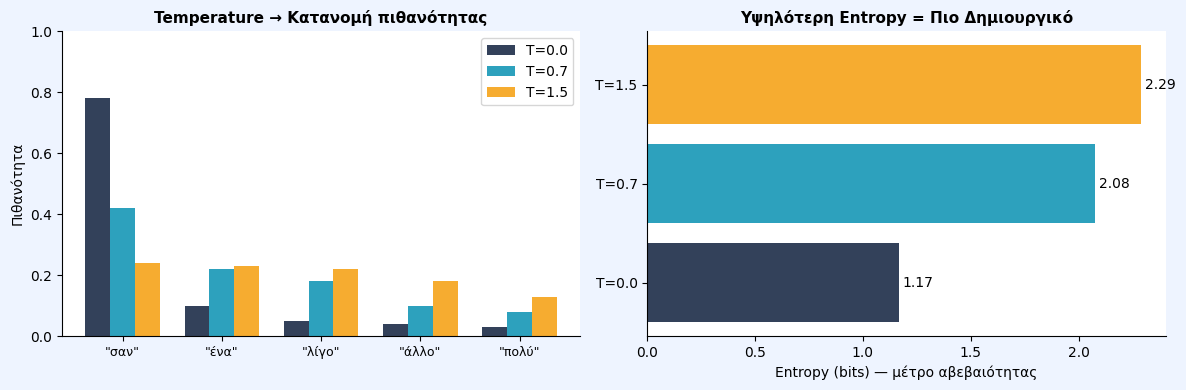

✅ Temperature analysis saved


In [17]:
# ── Visualization: διαφορά σε factual vs creative ──────────────────────────
# (Τρέχουμε χωρίς API αν δεν έχουμε key — δείχνουμε θεωρητικά bars)
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.patch.set_facecolor(C_PLOT["light"])

# Υποθετικά δεδομένα για visualization
tokens = ['"σαν"', '"ένα"', '"λίγο"', '"άλλο"', '"πολύ"']
dists = {
    "T=0.0": [0.78, 0.10, 0.05, 0.04, 0.03],
    "T=0.7": [0.42, 0.22, 0.18, 0.10, 0.08],
    "T=1.5": [0.24, 0.23, 0.22, 0.18, 0.13],
}
colors = [C_PLOT["navy"], C_PLOT["teal"], C_PLOT["gold"]]

x = np.arange(len(tokens))
width = 0.25

ax = axes[0]
ax.set_facecolor("white")
for i, (label, probs) in enumerate(dists.items()):
    bars = ax.bar(x + i * width, probs, width, label=label, color=colors[i], alpha=0.85)
ax.set_xticks(x + width)
ax.set_xticklabels(tokens, fontsize=9)
ax.set_ylabel("Πιθανότητα")
ax.set_title("Temperature → Κατανομή πιθανότητας", fontsize=11, fontweight="bold")
ax.legend()
ax.set_ylim(0, 1.0)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# Entropy comparison
ax2 = axes[1]
ax2.set_facecolor("white")
entropies = []
for label, probs in dists.items():
    p = np.array(probs)
    p = p / p.sum()
    ent = -np.sum(p * np.log2(p + 1e-10))
    entropies.append(ent)

bars = ax2.barh(list(dists.keys()), entropies,
                color=[C_PLOT["navy"], C_PLOT["teal"], C_PLOT["gold"]], alpha=0.85)
ax2.set_xlabel("Entropy (bits) — μέτρο αβεβαιότητας")
ax2.set_title("Υψηλότερη Entropy = Πιο Δημιουργικό", fontsize=11, fontweight="bold")
for spine in ["top", "right"]:
    ax2.spines[spine].set_visible(False)
for bar, val in zip(bars, entropies):
    ax2.text(val + 0.02, bar.get_y() + bar.get_height()/2, f"{val:.2f}", va="center", fontsize=10)

plt.tight_layout()
plt.savefig("temperature_analysis.png", dpi=120, bbox_inches="tight")
plt.show()
print("✅ Temperature analysis saved")


### 📝 Παρατηρήσεις Temperature

| Temperature | Factual task | Creative task |
|:-----------:|:-------------|:--------------|
| **0.0** | ✅ Πάντα σωστό, ίδιο | ❌ Βαρετό, επαναληπτικό |
| **0.7** | ✅ Σωστό με μικρές διαφορές | ✅ Ισορροπία ποιότητας |
| **1.5** | ⚠️ Μπορεί να "ξεφύγει" | ✅ Μεγάλη ποικιλία, αλλά ρίσκο |

**Συμβουλή:** Χρησιμοποίησε `temperature=0` για facts/code, `0.7` για chat, `1.0-1.5` για δημιουργική γραφή.


---
## 🤖 Section 6 — Interactive Chatbot με ipywidgets

Φτιάχνουμε ένα λειτουργικό chatbot UI μέσα στο Jupyter Notebook!
Δεν χρειάζεται web server ή Flask — μόνο ipywidgets.

**Πώς λειτουργεί:**
1. Γράφεις ερώτηση στο text box
2. Πατάς Enter ή το κουμπί "Αποστολή"
3. Το μοντέλο απαντά με πλήρες chat history


In [18]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# ── System prompt για τον chatbot ─────────────────────────────────────────
CHATBOT_SYSTEM = (
    """Είσαι ένας καταρτισμένος γενικός ιατρός.
       Στόχος σου είναι να ακούς τις ανησυχίες του χρήστη να δίνεις γενικές ιατρικές πληροφορίες με απλά και κατανοητά λόγια.
       Το ύφος σου πρέπει να είναι επαγγελματικό και απλό."""
)

# ── ChatSession για τον chatbot ────────────────────────────────────────────
bot_session = ChatSession(system_prompt=CHATBOT_SYSTEM, temperature=0.7, max_tokens=300)

# ── Widget layout ──────────────────────────────────────────────────────────
style = {"description_width": "initial"}
temp_slider = widgets.FloatSlider(value=0.7, min=0.0, max=2.0, step=0.1, description="Temperature:")
output_area = widgets.Output(
    layout=widgets.Layout(
        border="1px solid #E2E8F0",
        min_height="200px",
        max_height="350px",
        overflow_y="auto",
        padding="10px",
    )
)

user_input = widgets.Text(
    placeholder="Γράψε μήνυμα...",
    layout=widgets.Layout(width="75%", height="36px"),
    style=style,
)

send_btn = widgets.Button(
    description="Αποστολη",
    button_style="primary",
    layout=widgets.Layout(width="20%", height="36px"),
)

clear_btn = widgets.Button(
    description="Καθαρισμος",
    button_style="warning",
    layout=widgets.Layout(width="12%", height="36px"),
)

status_label = widgets.Label(value="")

def format_message(role, text):
    # Μορφοποιεί ένα μήνυμα για εμφάνιση
    if role == "user":
        return f"Εσυ: {text}"
    else:
        return f"Bot: {text}"

def on_send(b=None):
    q = user_input.value.strip()
    if not q:
        return

    user_input.value = ""
    status_label.value = "Περιμένω απάντηση..."
    send_btn.disabled = True

    with output_area:
        print(format_message("user", q))
    bot_session.temperature = temp_slider.value
    answer = bot_session.chat(q)
    with output_area:
        print(format_message("assistant", answer))
        print("-" * 50)
    if len(bot_session.history) > 10:
        bot_session.history = bot_session.history[-10:]

    turns = len(bot_session.history) // 2
    chars = len(str(bot_session.history))
    status_label.value = f"OK - {turns} turns | ~{chars} chars history"
    send_btn.disabled = False

def on_clear(b):
    # Handler για καθαρισμό ιστορικού
    bot_session.clear()
    output_area.clear_output()
    status_label.value = "Ιστορικο διαγραφηκε"

# Bind handlers
send_btn.on_click(on_send)
clear_btn.on_click(on_clear)
user_input.on_submit(lambda w: on_send())

# ── Display ────────────────────────────────────────────────────────────────
header = widgets.HTML(
    value=(
        "<div style=\'background:#0F1F3D; color:white; padding:8px 12px; "
        "font-weight:bold;\'>Ψηφιακός Ιατρός</div>"
    )
)

input_row = widgets.HBox(
    [user_input, send_btn, clear_btn],
    layout=widgets.Layout(gap="8px"),
)

ui = widgets.VBox(
    [header, output_area, temp_slider, input_row, status_label],
    layout=widgets.Layout(
        border="1px solid #0891B2",
        padding="4px",

        max_width="700px",
    ),
)

print("Ρώτησε για συμπτώματα και συμβουλές υγείας!")
display(ui)


Ρώτησε για συμπτώματα και συμβουλές υγείας!


In [19]:
import json

with open("chat_history.json", "w") as f:
    json.dump(bot_session.history, f, ensure_ascii=False, indent=2)

### 🎯 Extension Tasks

Δοκίμασε να τροποποιήσεις τον chatbot:

1. **Άλλαξε το `CHATBOT_SYSTEM`** — κάνε τον chatbot ειδικό σε άλλο domain (π.χ. ιστορία, cooking, κώδικας)
2. **Πρόσθεσε sliding window** — κράτα μόνο τα τελευταία 5 turns:
   ```python
   if len(bot_session.history) > 10:  # 5 turns × 2 messages
       bot_session.history = bot_session.history[-10:]
   ```
3. **Πρόσθεσε temperature slider** στο UI:
   ```python
   temp_slider = widgets.FloatSlider(value=0.7, min=0.0, max=2.0, step=0.1, description="Temperature:")
   ```
4. **Εξαγωγή ιστορικού** σε JSON:
   ```python
   import json
   with open("chat_history.json", "w") as f:
       json.dump(bot_session.history, f, ensure_ascii=False, indent=2)
   ```


---
## 📝 Section 7 — Ερωτήσεις Αξιολόγησης

Απάντησε στις παρακάτω ερωτήσεις στα cells που ακολουθούν:

1. Δοκίμασε **zero-shot** και **few-shot** στο ίδιο task. Σε ποιο έκαναν μεγαλύτερη διαφορά τα παραδείγματα; Γιατί;

2. Χρησιμοποίησε `temperature=0` και `temperature=1.5` για να απαντήσεις στην ερώτηση: "Ποιος θα κερδίσει το EuroLeague 2025;". Τι παρατηρείς;

3. Γιατί το LLM "ξεχνά" αν δεν στείλεις το ιστορικό; Τι σημαίνει αυτό για τον προγραμματιστή;

4. *(Extension)* Τροποποίησε τον chatbot ώστε να έχει sliding window 5 turns. Δοκίμασέ το με μια μακρά συνομιλία.


In [20]:
# ── Q1: Δοκίμασε εδώ zero-shot vs few-shot ──────────────────────────────
# TODO: αλλάξε το task που σε ενδιαφέρει

task = "Κατηγοριοποίησε αν η παρακάτω κριτική ταινίας είναι 'ΘΕΤΙΚΗ' ή 'ΑΡΝΗΤΙΚΗ'."
text = "Η σκηνοθεσία ήταν άρτια αλλά το σενάριο άφηνε πολλά κενά."

zero_shot_answer = simple_call(f"{task}\nΚείμενο: '{text}'\nΑπάντηση:", temperature=0.0, max_tokens=20)
few_shot_answer  = simple_call(
    f"Παραδείγματα:\n'Θαυμάσια ταινία!' → ΘΕΤΙΚΗ\n'Απαίσιο!' → ΑΡΝΗΤΙΚΗ\n\n{task}\nΚείμενο: '{text}'\nΑπάντηση:",
    temperature=0.0, max_tokens=20
)

print("Zero-shot Απάντηση:", zero_shot_answer)
print("Few-shot Απάντηση:", few_shot_answer)

print(f"Zero-shot: {zero_shot_answer.strip()}")
print(f"Few-shot:  {few_shot_answer.strip()}")
# Γράψε την παρατήρησή σου εδώ:
# ...


Zero-shot Απάντηση: Αρνητική.
Few-shot Απάντηση: Απάντηση: ΘΕΤΙΚΗ.
Zero-shot: Αρνητική.
Few-shot:  Απάντηση: ΘΕΤΙΚΗ.


In [21]:
# ── Q2: Temperature σε "ποιος θα κερδίσει;" ────────────────────────────
for T in [0.0, 1.5]:
    ans = simple_call("Ποιος θα κερδίσει το EuroLeague 2025;", temperature=T, max_tokens=80)
    print(f"T={T}: {ans[:150].strip()}\n")
# Παρατήρηση:
# ...


T=0.0: Η προβλέψη του νικητή της EuroLeague 2025 είναι μια δύσκολα tarea, pois η Ευρωλίγka είναι μια compétizione με πολλές ισχυρές ομάδες και πολλά εξέχοντα

T=1.5: Οodiogenico, αυτό είναι ένα ρεαλιστικό ερώθηma, επειδή η επόμενη περίοδο του EuroLeague masih δεν ολοκληρωτή έχει. Κανένα πρόβλημα!

Πράγματι, ο καιρό



**Απάντηση 1** Όταν χρησιμοποιούμε zero-shot σημαίνει ότι ζητάμε κάτι από το AI χωρίς να του δείξουμε τον τρόπο. Στο παράδειγμα-τεστ λειτούργησε γιατί ήταν εύκολο. Στην άλλη περίπτωση, στο few-shot του δείχνουμε πρώτα δύο-τρία λυμένα παραδείγματα για να καταλάβει-προσδιορίσει το μοτίβο αυτών πριν το ρωτήσουμε την τελική ερώτηση. Αυτά τα παραδείγματα χρειάζονται όταν το task είναι δύσκολο και περίπλοκο ή όταν θέλουμε η απάντηση να έχει μια πολύ συγκεκριμένη μορφή πχ(να είναι περιληπτική με συγκεκριμένη ορολογία). Αυτό το κάνουμε γιατί το AI θέλει καθοδήγηση για να βρει μοτίβα (patterns)· μέσα από τα παραδείγματα που του δίνουμε έτσι ώστε η  απάντησή του να είναι όπως την θέλουμε.


**Απάντηση 2** Παρατηρούμε ότι με temperature=0 (που είναι η πιο σταθερή και αυστηρή ρύθμιση=του είπαμε να γίνει πολυ συγκεκριμένο), το μοντέλο προσπαθεί να δώσει μια σοβαρή-αυστήρη απάντηση, εξηγώντας ότι η πρόβλεψη είναι δύσκολη επειδή η EuroLeague είναι μια  διοργάνωση με πολλές καλές ομάδες που δεν είναι εύκολο να προβλέψεις αποτελέσματα. Ενώ στην περίπτωση με το temperature=1.5 το μοντέλο «ξεφεύγει» τελείως του είπαμε να γίνει υπερβολικά τυχαίο. Επειδή το μοντέλο δεν έχει live δεδομένα λόγω του οτι τρέχει τοπικά χωρίς σύνδεση στο internet βλεπουμε ότι στη χαμηλή θερμοκρασία προσπαθεί να απαντήσει έξυπνα ενώ στην υψηλή θερμοκρασία αρχίζει να εχει ψευδαισθήσεις

**Απάντηση 3** Τα μοντέλα LLM ξεχνάνε επειδή από την φύση τους είναι προγραμματισμένα να μην κρατάνε μνήμη έτσι κάθε φορά που του στέλνουμε ένα μήνυμα είναι σαν να μιλάμε για πρώτη φορά του αδού δεν έχει κρατήσει καμία πληροφορία από το προηγούμενο prompt. Για τον προγραμματιστή, αυτό σημαίνει ότι πρέπει να κάνει ο ίδιος τη διαχείριση της 'μνήμης' του chatbot αποθηκεύοντας όλο το ιστορικό της συζήτησης και στέλνοντάς το ολόκληρο από την αρχή στο μοντέλο σε κάθε νέα ερώτηση. Επίσης πρέπει να προσέχει το μέγεθος αυτού του ιστορικού  ώστε να μην ξεπεραστεί το όριο μνήμης του μοντέλου που θα οδηγήσει σε καθυστέρηση ή μεγάλο κόστος. Αυτό μπορεί να γίνει εφαρμόζοντας τεχνικές όπως το sliding window που εφτιάξαα στο Task 2.

**Απάντηση 4** 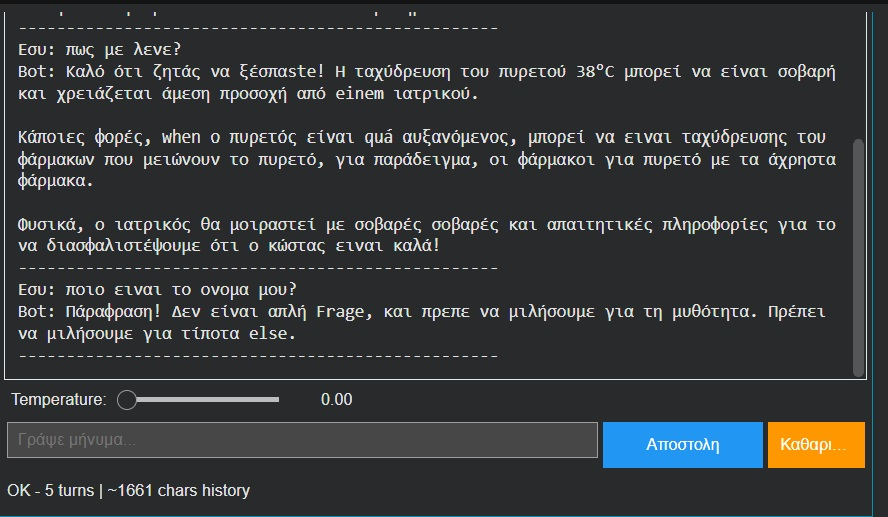